<div style="background:#232F3E;color:#FFFFFF;padding:18px 22px;border-radius:8px;">
<div style="color:#FF9900;font-weight:600;letter-spacing:.04em;font-size:0.9em;">Amazon Web Services – Labs · Stickler</div>
<h1 style="color:#FFFFFF;margin:6px 0 4px 0;">Warehouse 3D detection regression</h1>
<div style="font-size:1.05em;">Only required_match makes Stickler's default report count like a detector: two regressed checkpoints, real warehouse ground truth, three schemas.</div>
<div style="margin-top:12px;font-size:0.85em;line-height:2.1;">
<span style="border:1px solid #FFFFFF;border-radius:10px;padding:2px 8px;">Data: NVIDIA PhysicalAI-SmartSpaces, CC-BY-4.0</span> ·
<span style="border:1px solid #FFFFFF;border-radius:10px;padding:2px 8px;">CPU only, deterministic</span> ·
<span style="border:1px solid #FFFFFF;border-radius:10px;padding:2px 8px;">About 5 min run + 341 MB one-time download</span> ·
<span style="border:1px solid #FFFFFF;border-radius:10px;padding:2px 8px;">About 2.2 GB peak RAM</span> ·
<span style="border:1px solid #FF9900;border-radius:10px;padding:2px 8px;">Requires PR #539 (required_match, unreleased)</span>
</div>
</div>

Data: [nvidia/PhysicalAI-SmartSpaces](https://huggingface.co/datasets/nvidia/PhysicalAI-SmartSpaces),
CC-BY-4.0. Cite it as in [Citation](#Citation).

## TL;DR

**Only `required_match` makes Stickler's default report count like a detector.**

A detection benchmark counts a person predicted 1 m away as one miss plus one false alarm. Stickler's
default schema scores that pair 5/6 and calls it a match. On real warehouse ground truth with
synthetic predictions, two regressed checkpoints read like this:

| checkpoint | what Stickler reports | `default` | `strict` | `required_match` |
|---|---|---|---|---|
| `person_drop`: about 10% of people lost | overall F1 | 0.987 | 0.954 | **0.924** |
| | Person recall | 0.971 | 0.969 | **0.904** |
| | CI gate (0.95 bar) | PASS | PASS | **FAIL** |
| `near_vehicle_miss`: 4 in 10 people within 2 m of a vehicle lost | overall F1 | 0.995 | 0.985 | 0.976 |
| | Person recall | 0.990 | 0.990 | 0.969 |
| | near-vehicle recall (0.90 bar) | 0.867 | 0.815 | **0.589** |

- `person_drop` is the regression that hides: under `default` and `strict` the gate passes it.
- The near-vehicle slice rule catches `near_vehicle_miss` under all three schemas, but `default` and
  `strict` understate the loss: 13% and 18% of the slice lost, where `required_match` shows 41%.
- `strict` read with `recall_with_fd=True` reaches the same recall (`person_drop` 0.911 vs 0.911; the
  slice 0.586 vs 0.589), but its misses stay labelled FD, not FN plus FA, and its counts match a
  nuScenes-style greedy matcher on only 8 to 72 of 200 frames in the regressed checkpoints.

## What you will learn

- Why a weighted similarity score is not a detection match, and the flag that fixes it:
  `ComparableField(required_match=True)`.
- Why `match_threshold = 1.0` is not enough: it rejects the same pairs, but as FDs that Stickler's
  default recall leaves out.
- How to score a safety slice (people near vehicles) from the same assignment as the overall metric.
- How Stickler's counts compare with a nuScenes-style greedy matcher, and how to turn the result into
  a CI gate that fails with a reason.

## Before you run

| | |
|---|---|
| Reading time | about 12 min; about 3 min for the TL;DR, section 4 and section 7 |
| Run time | about 5 min on CPU (306 s measured, Python 3.12), deterministic |
| Download | 341 MB `ground_truth.json` and 136 KB `calibration.json`, once, to the Hugging Face cache or `SMARTSPACES_CACHE_DIR`; about 1 min at 50 Mbit/s. Nothing is written to the repo. |
| Memory | about 2.2 GB peak while the JSON is parsed (printed in section 2); keep 3 GB free |

```bash
pip install "git+https://github.com/awslabs/stickler@refs/pull/539/head" "huggingface_hub>=0.25" "matplotlib>=3.8"
```

A local checkout of that branch works too: `pip install /path/to/stickler-checkout`. Once #539 is
released, the first line becomes `pip install "stickler-eval>=X.Y.Z"`, with the first release that
includes it.

> **Warning:** `ComparableField(required_match=...)` comes from PR #539 and is not released, so the
> install must come from that PR; Setup stops with a clear error otherwise. Check the printed
> `stickler file` path before you trust a number: a pip install and a checkout often report the same
> version (`AGENTS.md`, "Measuring behaviour by hand").

## Configuration

Every knob in one place. The radius sweep in section 3 justifies the 2.0 m.

In [1]:
# The asserts check the shipped values. Change a knob and some asserts are expected to fail.
DATASET = "nvidia/PhysicalAI-SmartSpaces"
REVISION = "d38193be60906679124732a4be9a6516821e2bed"  # main on 2026-11-06
SCENE = "MTMC_Tracking_2025/train/Warehouse_001"
N_FRAMES = 200                 # frames sampled from the 9,000 in the scene
SAMPLE_SEED = 538

POSITION_TOLERANCE_M = 0.5     # m, per axis
CLASS_WEIGHT = 3.0             # the class weighs 3, each axis 1
NEAR_VEHICLE_RADIUS_M = 2.0    # m, safety slice: a person this close to a vehicle center
JITTER_M = 0.3                 # m, in-tolerance noise added to every prediction, per axis
MOVE_M = 1.0                   # m, a moved object moves this far along x or y

PERSON_DROP_RATE = 0.10        # share of all people that fail in person_drop
NEAR_VEHICLE_FAIL_RATE = 0.40  # share of slice people that fail in near_vehicle_miss
DROP_SHARE = 0.3               # of the failing people, the share dropped; the rest are moved
SWAP_RATE = 0.5                # NovaCarter/Transporter label swap probability in class_confusion
VARIANT_SEEDS = {"near_vehicle_miss": 4, "clean": 1, "person_drop": 2, "class_confusion": 3}

GATE = {"overall_f1_min": 0.95, "person_recall_min": 0.95, "class_recall_min": 0.90,
        "near_vehicle_recall_min": 0.90}

## Setup

Helpers. Expand to read; nothing here is needed to follow the story. The outputs below show which
stickler tree ran and that the preflight checks passed.

In [2]:
import hashlib
import inspect
import json
import math
import os
import platform
import random
import re
import sys
import time
import warnings
from collections import Counter
from typing import List

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Patch

try:
    import resource  # not on Windows
except ImportError:
    resource = None

# huggingface_hub imports tqdm.auto, which warns when ipywidgets is absent; the bars are not needed.
warnings.filterwarnings("ignore", message="IProgress not found")
from huggingface_hub import hf_hub_download  # noqa: E402
from huggingface_hub.utils import HfHubHTTPError, LocalEntryNotFoundError  # noqa: E402

import stickler  # noqa: E402
from stickler import (  # noqa: E402
    ComparableField,
    ExactComparator,
    NonMatchType,
    NumericComparator,
    StructuredModel,
    aggregate_from_comparisons,
)

# Which tree ran: a pip install and a checkout often report the same version.
print("stickler file   :", inspect.getfile(stickler))
print("stickler version:", stickler.__version__)
print("python          :", platform.python_version())
NOTEBOOK_START = time.perf_counter()

# Preflight: fail fast, with the fix, before the download.
if "required_match" not in inspect.signature(ComparableField).parameters:
    raise RuntimeError(
        "This notebook needs ComparableField(required_match=...) from #539. Install stickler from that "
        "branch; the printed 'stickler file' path shows which tree you imported.")
print("preflight       : ComparableField(required_match=...) is available")

stickler file   : /work/src/stickler/__init__.py
stickler version: 1.0.2
python          : 3.12.16
preflight       : ComparableField(required_match=...) is available


In [3]:
# ---- Scoring: one frame, counts, aggregation
COUNT_KEYS = ("tp", "fd", "fa", "fn")
OBJECT_ROW = re.compile(r"dets\[\d+\]")  # "dets[3]" is an object; "dets[3].x" is one of its fields


def compare(schema, gt_dets, pred_dets):
    Det, Frame = SCHEMAS[schema]
    return Frame(dets=[Det(**d) for d in gt_dets]).compare_with(
        Frame(dets=[Det(**d) for d in pred_dets]),
        include_confusion_matrix=True,
        document_non_matches=True,
    )


def frame_counts(result):
    overall = result["confusion_matrix"]["fields"]["dets"]["overall"]
    return {k: overall[k] for k in COUNT_KEYS}


def run(schema, preds, only_class=None):
    keep = (lambda dets: dets) if only_class is None else (
        lambda dets: [d for d in dets if d["cls"] == only_class])
    return {fid: compare(schema, keep(GT[fid]), keep(preds[fid])) for fid in GT}


def rounded(value):
    return round(value, 6)


def summarize(results):
    m = aggregate_from_comparisons(list(results.values())).field_metrics["dets"]
    summary = {k: m[k] for k in COUNT_KEYS}
    summary.update(precision=rounded(m["cm_precision"]), recall=rounded(m["cm_recall"]),
                   f1=rounded(m["cm_f1"]),
                   recall_with_fd=rounded(m["tp"] / (m["tp"] + m["fn"] + m["fd"])))
    return summary


def metric(table, name, schema, key):
    return RESULTS[table][f"{name}/{schema}"][key]


def peak_memory_gb():
    # ru_maxrss is KiB on Linux and bytes on macOS; None where it is unknown.
    if resource is None or sys.platform not in ("linux", "darwin"):
        return None
    rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return rss / 1024**3 if sys.platform == "darwin" else rss / 1024**2


# ---- Data: download at the pinned revision, sample frames
def download(name):
    try:
        return hf_hub_download(repo_id=DATASET, repo_type="dataset", revision=REVISION,
                               filename=f"{SCENE}/{name}",
                               cache_dir=os.environ.get("SMARTSPACES_CACHE_DIR"))
    except (LocalEntryNotFoundError, HfHubHTTPError, OSError) as error:
        raise RuntimeError(
            f"Could not fetch {SCENE}/{name} from {DATASET} at revision {REVISION}. Manual download: "
            f"https://huggingface.co/datasets/{DATASET}/blob/{REVISION}/{SCENE}/{name}. Check network "
            "access to huggingface.co (a proxy may need HTTPS_PROXY), that HF_HUB_OFFLINE is unset, and "
            "that at least 400 MB of disk is free; or set SMARTSPACES_CACHE_DIR to a Hugging Face cache "
            "that already holds the file."
        ) from error


def load_ground_truth():
    with open(download("ground_truth.json")) as f:
        raw_gt = json.load(f)
    with open(download("calibration.json")) as f:
        calibration = json.load(f)
    first = next(iter(raw_gt.values()))[0]
    if not {"object type", "3d location"} <= first.keys():
        raise KeyError(f"expected 'object type' and '3d location' at revision {REVISION[:12]}, "
                       f"found {sorted(first)}")
    frame_ids = sorted(random.Random(SAMPLE_SEED).sample(sorted(raw_gt, key=int), N_FRAMES), key=int)
    gt = {}       # frame id -> list of {cls, x, y, z}
    scales = []   # (cls, w, l, h, z) of every sampled box, for the units check
    for fid in frame_ids:
        gt[fid] = []
        for obj in raw_gt[fid]:
            x, y, z = obj["3d location"]
            gt[fid].append(dict(cls=obj["object type"], x=x, y=y, z=z))
            scales.append((obj["object type"], *obj["3d bounding box scale"], z))
    return gt, scales, calibration, len(raw_gt)


# ---- The safety slice
VEHICLES = {"Forklift", "NovaCarter", "Transporter"}


def nearest_vehicle(det, gt_dets):
    # Distance between 3D box centers, to the closest ground truth vehicle in the same frame.
    return min((math.dist((det["x"], det["y"], det["z"]), (v["x"], v["y"], v["z"])), v["cls"])
               for v in gt_dets if v["cls"] in VEHICLES)


def is_near_vehicle_person(det, gt_dets):
    return det["cls"] == "Person" and nearest_vehicle(det, gt_dets)[0] <= NEAR_VEHICLE_RADIUS_M


def near_vehicle_summary(results):
    # Read from the joint assignment: a slice person is missed if listed as FN, or as the ground
    # truth of an FD, in the frame's object-level non_matches.
    people = fn = fd = 0
    for fid, result in results.items():
        people += sum(is_near_vehicle_person(d, GT[fid]) for d in GT[fid])
        for nm in result["non_matches"]:
            gt_det = nm["ground_truth_value"]
            if not OBJECT_ROW.fullmatch(nm["field_path"]) or gt_det is None:
                continue
            if is_near_vehicle_person(gt_det, GT[fid]):
                fn += nm["non_match_type"] == NonMatchType.FALSE_NEGATIVE
                fd += nm["non_match_type"] == NonMatchType.FALSE_DISCOVERY
    tp = people - fn - fd
    return dict(people=people, tp=tp, fd=fd, fn=fn, recall=rounded(tp / (tp + fn)),
                recall_with_fd=rounded(tp / people))


# ---- Synthetic checkpoints
VEHICLE_SWAP = {"NovaCarter": "Transporter", "Transporter": "NovaCarter"}


def make_variant(name, seed):
    rng = random.Random(seed)
    frames = {}
    for fid, gt_dets in GT.items():
        preds = []
        for d in gt_dets:
            p = {**d, **{a: d[a] + rng.uniform(-JITTER_M, JITTER_M) for a in ("x", "y", "z")}}
            fails = ((name == "person_drop" and d["cls"] == "Person" and rng.random() < PERSON_DROP_RATE)
                     or (name == "near_vehicle_miss" and is_near_vehicle_person(d, gt_dets)
                         and rng.random() < NEAR_VEHICLE_FAIL_RATE))
            if fails:
                if rng.random() < DROP_SHARE:
                    continue  # dropped
                p[rng.choice(("x", "y"))] += rng.choice((-MOVE_M, MOVE_M))  # moved
            if name == "class_confusion" and d["cls"] in VEHICLE_SWAP and rng.random() < SWAP_RATE:
                p["cls"] = VEHICLE_SWAP[d["cls"]]
            preds.append(p)
        rng.shuffle(preds)
        frames[fid] = preds
    return frames


def score_variant(name, preds):
    # Fills RESULTS (overall, slice, Person, per class) and FRAME_COUNTS for one variant.
    for schema in SCHEMA_NAMES:
        key = f"{name}/{schema}"
        results = run(schema, preds)
        FRAME_COUNTS[name, schema] = {fid: frame_counts(r) for fid, r in results.items()}
        RESULTS["overall"][key] = summarize(results)
        RESULTS["near_vehicle"][key] = near_vehicle_summary(results)
        RESULTS["person"][key] = summarize(run(schema, preds, only_class="Person"))
        RESULTS["per_class"][key] = {
            cls: RESULTS["person"][key] if cls == "Person"
            else summarize(run(schema, preds, only_class=cls)) for cls in CLASSES}


# ---- Independent reference: nuScenes-style greedy center-distance matcher (no stickler)
def greedy_center_distance(gt_dets, pred_dets, max_distance=POSITION_TOLERANCE_M):
    counts = dict(tp=0, fd=0, fa=0, fn=0)
    for cls in {d["cls"] for d in gt_dets} | {d["cls"] for d in pred_dets}:
        unmatched_gt = [d for d in gt_dets if d["cls"] == cls]
        for p in (d for d in pred_dets if d["cls"] == cls):
            dists = [math.hypot(p["x"] - g["x"], p["y"] - g["y"]) for g in unmatched_gt]
            if dists and min(dists) <= max_distance:
                unmatched_gt.pop(dists.index(min(dists)))
                counts["tp"] += 1
            else:
                counts["fa"] += 1
        counts["fn"] += len(unmatched_gt)
    return counts


# ---- CI gate
def gate(name, schema, thresholds=GATE):
    key = f"{name}/{schema}"
    checks = [("overall F1", RESULTS["overall"][key]["f1"], thresholds["overall_f1_min"]),
              ("Person recall", RESULTS["person"][key]["recall"], thresholds["person_recall_min"])]
    checks += [(f"{cls} recall", m["recall"], thresholds["class_recall_min"])
               for cls, m in sorted(RESULTS["per_class"][key].items())]
    checks.append(("near-vehicle recall", RESULTS["near_vehicle"][key]["recall"],
                   thresholds["near_vehicle_recall_min"]))
    reasons = [f"{label} {value} < {minimum}" for label, value, minimum in checks if value < minimum]
    return {"passed": not reasons, "reasons": reasons}


def failed_rules(name, schema):
    return [reason.rsplit(" ", 3)[0] for reason in RESULTS["gate"][f"{name}/{schema}"]["reasons"]]


def fmt(det):
    return "-" if det is None else f"{det['cls']:8} ({det['x']:6.2f}, {det['y']:6.2f}, {det['z']:5.2f})"

In [4]:
# ---- Display: tables and figures. They only read RESULTS; nothing here changes a number.
# Okabe-Ito palette (colorblind safe). Hatching, markers and text labels repeat what color says.
SCHEMA_STYLE = {"default": ("#999999", "//"), "strict": ("#E69F00", ".."), "required_match": ("#0072B2", "")}
ALERT, PERSON, VEHICLE, INK = "#D55E00", "#56B4E9", "#000000", "#222222"
FAIL_TINT, PASS_TINT = "rgba(213,94,0,0.18)", "rgba(0,114,178,0.10)"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": INK, "xtick.color": INK,
    "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 110, "hatch.linewidth": 0.8,
})


def schema_bar(ax, pos, value, width, schema, horizontal=False):
    color, hatch = SCHEMA_STYLE[schema]
    draw = ax.barh if horizontal else ax.bar
    draw(pos, value, width, color=color, hatch=hatch, edgecolor="white", linewidth=0.5)


def schema_legend():
    return [Patch(facecolor=c, hatch=h, edgecolor="white", label=s) for s, (c, h) in SCHEMA_STYLE.items()]


def value_label(value, minimum):
    return (f"{value:.2f} ✗", ALERT, "bold") if value < minimum else (f"{value:.2f}", INK, "normal")


def html_table(header, rows):
    head = "".join(f"<th style='text-align:left'>{h}</th>" for h in header)
    body = "".join("<tr>" + "".join(f"<td style='text-align:left;{style}'>{text}</td>"
                                    for text, style in row) + "</tr>" for row in rows)
    return HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>")


def tiny_table(tiny, cases):
    def says(c):
        return " + ".join(f"{c[k]} {k.upper()}" for k in ("tp", "fd", "fn", "fa") if c[k])
    rows = [[(case, "")] + [(says(tiny[s, case]), "") for s in SCHEMA_NAMES] + [("1 FN + 1 FP", "")]
            for case in cases]
    return html_table(["case", *SCHEMA_NAMES, "detection convention"], rows)


METRIC_ROWS = (("tp", "overall", "tp"), ("fd", "overall", "fd"), ("fa", "overall", "fa"),
               ("fn", "overall", "fn"), ("recall (cm_recall)", "overall", "recall"),
               ("recall_with_fd", "overall", "recall_with_fd"), ("F1 (cm_f1)", "overall", "f1"),
               ("Person recall", "person", "recall"), ("Person recall_with_fd", "person", "recall_with_fd"),
               ("near-vehicle recall", "near_vehicle", "recall"),
               ("near-vehicle recall_with_fd", "near_vehicle", "recall_with_fd"))


def metrics_table(name, bold=None, only=None):
    # bold: {row label: schemas whose cell the text discusses}; only: the row labels to show
    bold = bold or {}
    rows = []
    for label, table, key in METRIC_ROWS:
        if only and label not in only:
            continue
        row = [(label, "")]
        for s in SCHEMA_NAMES:
            value = RESULTS[table][f"{name}/{s}"][key]
            text = f"{value}" if isinstance(value, int) else f"{value:.3f}"
            row.append((f"<b>{text}</b>" if s in bold.get(label, ()) else text, "text-align:right"))
        rows.append(row)
    return html_table([f"<code>{name}</code>", *SCHEMA_NAMES], rows)


def gate_cell(value, minimum, prefix=""):
    if value >= minimum:
        return f"{prefix}✓ {value:.3f}", ""
    return f"<b>{prefix}✗ {value:.3f} &lt; {minimum:.2f}</b>", f"background:{FAIL_TINT}"


def per_class_table():
    rows = [[(f"<code>{key.split('/')[0]}</code>", ""), (key.split("/")[1], "")]
            + [gate_cell(per_class[c]["recall"], GATE["class_recall_min"]) for c in CLASSES]
            for key, per_class in RESULTS["per_class"].items()]
    return html_table(["variant", "schema", *(f"{c} recall" for c in CLASSES)], rows)


def gate_table():
    rows = []
    for key, decision in RESULTS["gate"].items():
        name, schema = key.split("/")
        low_cls, low = min(((c, m["recall"]) for c, m in RESULTS["per_class"][key].items()),
                           key=lambda item: item[1])
        verdict = ("PASS", f"background:{PASS_TINT}") if decision["passed"] else (
            "<b>FAIL</b>", f"background:{FAIL_TINT}")
        rows.append([(f"<code>{name}</code>", ""), (schema, ""),
                     gate_cell(RESULTS["overall"][key]["f1"], GATE["overall_f1_min"]),
                     gate_cell(RESULTS["person"][key]["recall"], GATE["person_recall_min"]),
                     gate_cell(low, GATE["class_recall_min"], f"{low_cls} "),
                     gate_cell(RESULTS["near_vehicle"][key]["recall"], GATE["near_vehicle_recall_min"]),
                     verdict])
    return html_table(["variant", "schema", "overall F1", "Person recall", "lowest class recall",
                       "near-vehicle recall", "decision"], rows)


OVERVIEW_PANELS = (("person_drop", "person_drop (10% of people lost)\npasses under default and strict"),
                   ("near_vehicle_miss", "near_vehicle_miss\nslice rule fails under all three"),
                   ("class_confusion", "class_confusion\nthese pass; the robots fail (Fig. 3)"))


def overview_label(value, minimum):
    # 3 decimals near a gate, where 2 would hide which side of it the value is on.
    text = f"{value:.3f}" if abs(value - minimum) < 0.01 else f"{value:.2f}"
    return (f"✗\n{text}", ALERT, "bold") if value < minimum else (text, INK, "normal")


def plot_overview():
    groups = (("overall\nF1", "overall", "f1", GATE["overall_f1_min"]),
              ("Person\nrecall", "person", "recall", GATE["person_recall_min"]),
              ("near-vehicle\nrecall", "near_vehicle", "recall", GATE["near_vehicle_recall_min"]))
    fig, axes = plt.subplots(1, len(OVERVIEW_PANELS), figsize=(13.5, 4.8), sharey=True)
    for ax, (name, title) in zip(axes, OVERVIEW_PANELS):
        for g, (_, table, key, minimum) in enumerate(groups):
            for s, schema in enumerate(SCHEMA_NAMES):
                value, x = RESULTS[table][f"{name}/{schema}"][key], g + (s - 1) * 0.3
                schema_bar(ax, x, value, 0.28, schema)
                text, color, weight = overview_label(value, minimum)
                ax.text(x, max(value, minimum) + 0.02, text, ha="center", va="bottom", fontsize=8.5,
                        color=color, fontweight=weight, zorder=4)
            ax.hlines(minimum, g - 0.45, g + 0.45, colors=INK, linestyles="--", linewidth=1.2, zorder=2)
        ax.set_title(title, fontsize=10, loc="left", fontweight="bold")
        ax.set_xticks(range(len(groups)), [g[0] for g in groups], fontsize=9)
        ax.set_ylim(0, 1.2)
        ax.set_yticks(np.arange(0, 1.01, 0.2))
        ax.grid(axis="y", color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Stickler metric (0 to 1)")
    handles = schema_legend() + [Line2D([], [], color=INK, ls="--", label="gate minimum")]
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False)
    fig.suptitle("person_drop passes under default and strict; only required_match fails it",
                 x=0.01, ha="left", fontweight="bold", fontsize=12)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()


def plot_scene(fid, rows):
    gt = GT[fid]
    vehicles = [d for d in gt if d["cls"] in VEHICLES]
    fig, ax = plt.subplots(figsize=(11, 6.2))
    people = np.array([(d["x"], d["y"]) for d in gt if d["cls"] == "Person"])
    person_z = float(np.median([d["z"] for d in gt if d["cls"] == "Person"]))
    ax.scatter(*people.T, s=14, color=PERSON, alpha=0.8, zorder=2)
    for v in vehicles:
        # The slice is a 3D sphere around the vehicle center; draw its cut at the median person height.
        radius = math.sqrt(max(NEAR_VEHICLE_RADIUS_M**2 - (person_z - v["z"]) ** 2, 0.0))
        ax.add_patch(Circle((v["x"], v["y"]), radius, facecolor=(0.6, 0.6, 0.6, 0.15),
                            edgecolor="#555555", linestyle="--", zorder=1))
        ax.scatter(v["x"], v["y"], marker="s", s=60, color=VEHICLE, zorder=3)
        ax.annotate(v["cls"], (v["x"], v["y"]), xytext=(0, -15), textcoords="offset points",
                    ha="center", fontsize=8)
    fns = [nm["ground_truth_value"] for nm in rows if nm["non_match_type"] == NonMatchType.FALSE_NEGATIVE]
    fas = [nm["prediction_value"] for nm in rows if nm["non_match_type"] == NonMatchType.FALSE_ALARM]
    ax.scatter([d["x"] for d in fns], [d["y"] for d in fns], s=230, facecolors="none",
               edgecolors=ALERT, linewidths=2, zorder=4)
    ax.scatter([d["x"] for d in fas], [d["y"] for d in fas], marker="x", s=70, color=ALERT,
               linewidths=2, zorder=4)
    free = list(fas)
    for g in fns:
        # A moved prediction lands within MOVE_M plus the jitter of its ground truth.
        near = [p for p in free if math.dist((g["x"], g["y"]), (p["x"], p["y"])) <= MOVE_M + 2 * JITTER_M]
        partner = min(near, key=lambda p: math.dist((g["x"], g["y"]), (p["x"], p["y"])), default=None)
        if partner:
            free.remove(partner)
            ax.annotate("", xy=(partner["x"], partner["y"]), xytext=(g["x"], g["y"]),
                        arrowprops=dict(arrowstyle="->", color=ALERT, lw=1.3), zorder=5)
        ax.annotate("moved 1 m" if partner else "dropped", (g["x"], g["y"]), xytext=(0, 13),
                    textcoords="offset points", ha="center", fontsize=8, color=ALERT, fontweight="bold")
    # Crop to the vehicles plus a 3.5 m margin (every miss is there), pushed past any person on the edge.
    for axis, set_lim in (("x", ax.set_xlim), ("y", ax.set_ylim)):
        lo = min(v[axis] for v in vehicles) - 3.5
        hi = max(v[axis] for v in vehicles) + 3.5
        lo = min([lo] + [d[axis] - 0.4 for d in gt if lo - 0.4 < d[axis] < lo + 0.4])
        hi = max([hi] + [d[axis] + 0.4 for d in gt if hi - 0.4 < d[axis] < hi + 0.4])
        set_lim(lo, hi)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(f"Frame {fid}: every person it missed stands next to a vehicle",
                 loc="left", fontweight="bold", fontsize=11)
    handles = [Line2D([], [], marker="o", ls="", color=PERSON, label="person (ground truth)"),
               Line2D([], [], marker="s", ls="", color=VEHICLE, label="vehicle center"),
               Patch(facecolor=(0.6, 0.6, 0.6, 0.15), edgecolor="#555555", linestyle="--",
                     label=f"{NEAR_VEHICLE_RADIUS_M:.0f} m slice at person height"),
               Line2D([], [], marker="o", ls="", markersize=12, markerfacecolor="none",
                      markeredgecolor=ALERT, markeredgewidth=2, label="missed person (FN)"),
               Line2D([], [], marker="x", ls="", markersize=8, color=ALERT, markeredgewidth=2,
                      label="false alarm (FA)")]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
    fig.tight_layout()
    plt.show()


def plot_class_confusion():
    name = "class_confusion"
    rows = [("Overall F1 (all classes)", "overall", None, GATE["overall_f1_min"])]
    rows += [(f"{c} (n={class_counts[c]:,})", "per_class", c, GATE["class_recall_min"])
             for c in sorted(CLASSES, key=class_counts.get, reverse=True)]
    fig, ax = plt.subplots(figsize=(9, 4.6))
    for r, (_, table, cls, minimum) in enumerate(rows):
        for s, schema in enumerate(SCHEMA_NAMES):
            m = RESULTS[table][f"{name}/{schema}"]
            value, y = (m["f1"] if cls is None else m[cls]["recall"]), r + (s - 1) * 0.27
            schema_bar(ax, y, value, 0.25, schema, horizontal=True)
            text, color, weight = value_label(value, minimum)
            ax.text(value + 0.01, y, text, va="center", fontsize=8, color=color, fontweight=weight)
        ax.vlines(minimum, r - 0.42, r + 0.42, colors=INK, linestyles="--", linewidth=1.2)
    ax.axhline(0.5, color="#BBBBBB", linewidth=0.8)
    ax.set_yticks(range(len(rows)), [row[0] for row in rows])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.15)
    ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.grid(axis="x", color="#DDDDDD", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.set_xlabel("recall (F1 for the top row), 0 to 1")
    ax.set_title("class_confusion: two robot classes fail while overall F1 stays at 0.98",
                 loc="left", fontweight="bold", fontsize=11)
    handles = schema_legend() + [Line2D([], [], color=INK, ls="--", label="gate minimum")]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    fig.tight_layout()
    plt.show()


def plot_agreement():
    names, n = list(VARIANTS), len(GT)
    fig, ax = plt.subplots(figsize=(9, 4.4))
    for v, name in enumerate(names):
        for s, schema in enumerate(SCHEMA_NAMES):
            equal, y = RESULTS["greedy"][name]["equal_frames"][schema], v + (s - 1) * 0.27
            schema_bar(ax, y, equal, 0.25, schema, horizontal=True)
            ax.text(equal + 2, y, f"{equal}/{n}", va="center", fontsize=8)
    ax.set_yticks(range(len(names)), names)
    ax.invert_yaxis()
    ax.set_xlim(0, n * 1.12)
    ax.set_xlabel(f"frames where Stickler's tp, fd, fa, fn equal the greedy matcher's (of {n})")
    top = ax.secondary_xaxis("top", functions=(lambda k: k / n * 100, lambda p: p * n / 100))
    top.set_xlabel("% of frames")
    ax.grid(axis="x", color="#DDDDDD", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.set_title("Under required_match, Stickler agrees with a greedy matcher on 92% or more of frames",
                 loc="left", fontweight="bold", fontsize=11, pad=10)
    ax.legend(handles=schema_legend(), loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    fig.tight_layout()
    plt.show()

## 1. The problem: a wrong detection that still counts as a match

A detector reports each object as a class plus a 3D position. Take one ground truth forklift at the
origin and one prediction, and score them under three schemas that differ only in how a wrong field is
counted (#538). Every field has `threshold=1.0`; the class weighs 3 and each axis 1.

| schema | how it is set | a forklift predicted 1.0 m off counts as |
|---|---|---|
| `default` | `match_threshold` 0.7, the score a pair needs to count as matched | TP: the pair scores 5/6 |
| `strict` | `match_threshold = 1.0` on `Det` | FD: still matched, with a wrong value |
| `required_match` | `ComparableField(required_match=True)` (#539) | FN plus FA, as a detector counts it |

The `Det` schema is the API this notebook teaches:

In [5]:
SCHEMA_NAMES = ("default", "strict", "required_match")


def make_schema(name):
    required = name == "required_match"  # True: every field is a hard requirement

    def field(comparator, weight=1.0):
        return ComparableField(comparator=comparator, threshold=1.0, weight=weight,
                               required_match=required)

    class Det(StructuredModel):
        match_threshold = 1.0 if name == "strict" else 0.7  # pair score needed to count as a TP
        cls: str = field(ExactComparator(), weight=CLASS_WEIGHT)  # exact class
        x: float = field(NumericComparator(absolute_tolerance=POSITION_TOLERANCE_M))  # within 0.5 m
        y: float = field(NumericComparator(absolute_tolerance=POSITION_TOLERANCE_M))  # within 0.5 m
        z: float = field(NumericComparator(absolute_tolerance=POSITION_TOLERANCE_M))  # within 0.5 m

    class Frame(StructuredModel):
        dets: List[Det] = ComparableField()  # Hungarian assignment between the two lists

    return Det, Frame


SCHEMAS = {name: make_schema(name) for name in SCHEMA_NAMES}

In [6]:
truth = dict(cls="Forklift", x=0.0, y=0.0, z=0.0)
TINY_CASES = {"x off 1.0 m": {"x": 1.0}, "y off 1.0 m": {"y": 1.0}, "class swap": {"cls": "Person"}}
tiny = {(schema, case): frame_counts(compare(schema, [truth], [{**truth, **change}]))
        for schema in SCHEMA_NAMES for case, change in TINY_CASES.items()}
display(tiny_table(tiny, TINY_CASES))

TP, FD, FN_FA = dict(tp=1, fd=0, fa=0, fn=0), dict(tp=0, fd=1, fa=0, fn=0), dict(tp=0, fd=0, fa=1, fn=1)
TINY_EXPECTED = {
    "default": {"x off 1.0 m": TP, "y off 1.0 m": TP, "class swap": FD},
    "strict": {"x off 1.0 m": FD, "y off 1.0 m": FD, "class swap": FD},
    "required_match": {name: FN_FA for name in TINY_CASES},
}
# A regression in #539, or in match_threshold handling, fails the run here.
for (schema, case), counts in tiny.items():
    assert counts == TINY_EXPECTED[schema][case], f"#538 case {case!r} under {schema}: {counts}"

case,default,strict,required_match,detection convention
x off 1.0 m,1 TP,1 FD,1 FN + 1 FA,1 FN + 1 FP
y off 1.0 m,1 TP,1 FD,1 FN + 1 FA,1 FN + 1 FP
class swap,1 FD,1 FD,1 FN + 1 FA,1 FN + 1 FP


`default` takes a 1.0 m position error as a match. `strict` rejects it, but as an FD: the pair stays
matched with a wrong value. Only `required_match` gives the two unmatched objects a detection
benchmark counts.

> **Note:** `required_match` is the detection rule "every field must be right or it is not that
> object". A pair with any required field below its threshold is removed *before* the Hungarian
> assignment (optimal one-to-one pairing, where COCO and nuScenes match greedily by confidence), so
> the ground truth stays an FN and the prediction stays an FA.

### Glossary

| Detection convention | Stickler | Meaning here |
|---|---|---|
| TP | `tp` | a matched pair whose score reaches `match_threshold` |
| FN (miss) | `fn` (false negative) | a ground truth object with no prediction paired to it |
| FP (false alarm) | `fa` (false alarm) | a prediction with no ground truth paired to it |
| *no equivalent; a detector counts 1 FN + 1 FP* | `fd` (false discovery) | a matched pair whose score is below `match_threshold`; Stickler's `fp` is `fd` + `fa` |
| precision | `cm_precision` = tp / (tp + fa + fd) | an FD is a wrong prediction |
| recall | `cm_recall` = tp / (tp + fn) | Stickler's default recall: it leaves FD out |
| recall with FD as a miss | `recall_with_fd=True`: tp / (tp + fn + fd) | an FD is also a missed object |
| per-sample error breakdown | `non_matches` | the per-object error list of one comparison |

Under `required_match`, `fd` is always 0, so `cm_precision` and `cm_recall` reduce to the usual
detection formulas.

## 2. The data: SmartSpaces Warehouse_001 ground truth

Real ground truth at the pinned revision in Configuration:
`MTMC_Tracking_2025/train/Warehouse_001/ground_truth.json` (341 MB) and its `calibration.json`
(136 KB). The file holds 9,000 frames with 50 objects each; I sample 200. The dataset card writes the
keys as `object_type` and `3d_location`; the file at this revision uses spaces (`object type`,
`3d location`), and the loader raises a `KeyError` if that changes.

In [7]:
t0 = time.perf_counter()
GT, SCALES, calibration, n_frames_in_file = load_ground_truth()
class_counts = Counter(d["cls"] for dets in GT.values() for d in dets)
CLASSES = sorted(class_counts)
peak_gb = peak_memory_gb()

print(f"{n_frames_in_file} frames in file, {len(GT)} sampled, {sum(class_counts.values())} objects "
      f"({time.perf_counter() - t0:.1f} s" + (f", peak memory {peak_gb:.1f} GB)" if peak_gb else ")"))
print(dict(class_counts))

9000 frames in file, 200 sampled, 10000 objects (4.5 s, peak memory 2.2 GB)
{'Forklift': 400, 'NovaCarter': 200, 'Transporter': 200, 'Person': 9200}


Each frame has 46 Person, 2 Forklift, 1 NovaCarter and 1 Transporter: people are 92% of the objects,
the four vehicles 8%.

<details>
<summary>Why I trust that positions are in meters</summary>

The card does not state units. The collapsed cell below checks them from the values. The median
person is 1.86 m tall and the median forklift 2.15 m, the scene spans about 19 m by 29 m, the cameras
sit 2 to 3 m up, and a forklift's `z` is half its box height, so `3d_location` is the box center, not
the floor point. Meters, or the 0.5 m tolerance means nothing.

</details>

In [8]:
xyz = np.array([[d["x"], d["y"], d["z"]] for dets in GT.values() for d in dets])
xyz_range = [(round(float(lo), 2), round(float(hi), 2)) for lo, hi in zip(xyz.min(0), xyz.max(0))]
median_size = {cls: np.median(np.array([s[1:4] for s in SCALES if s[0] == cls]), 0)
               for cls in sorted(class_counts)}
forklift_z_over_h = float(np.median([s[4] / s[3] for s in SCALES if s[0] == "Forklift"]))
camera_heights = []
for sensor in calibration["sensors"]:
    extrinsic = np.array(sensor["extrinsicMatrix"])
    camera_heights.append(float((-extrinsic[:, :3].T @ extrinsic[:, 3])[2]))

# Meters, or the 0.5 tolerance means nothing.
assert 1.5 < median_size["Person"][2] < 2.1, median_size
assert 1.5 < median_size["Forklift"][2] < 3.0, median_size

print("x, y, z range:", xyz_range)
print("median box size (w, l, h):")
for cls, size in median_size.items():
    print(f"  {cls:12} {np.round(size, 2)}")
print("forklift z / box height:", round(forklift_z_over_h, 3))
print(f"camera height: {min(camera_heights):.2f} to {max(camera_heights):.2f} m ({len(camera_heights)} cameras)")

x, y, z range: [(-9.66, 8.91), (-11.75, 17.57), (0.13, 1.08)]
median box size (w, l, h):
  Forklift     [1.21 2.31 2.15]
  NovaCarter   [0.71 0.48 0.48]
  Person       [0.59 0.54 1.86]
  Transporter  [1.43 0.65 0.2 ]
forklift z / box height: 0.499
camera height: 2.00 to 3.00 m (42 cameras)


## 3. The scenario: a safety slice and four checkpoints

A frame is a `Frame(dets: List[Det])`, and Stickler pairs the two lists with the Hungarian algorithm.
Each frame's result goes to `aggregate_from_comparisons`, and every count is summed over the 200
frames.

### The safety slice: people near a vehicle

A person close to a forklift or a mobile robot is the case a warehouse safety system exists for, and
the case a camera is most likely to lose, because the vehicle occludes the person. The slice is every
Person whose 3D center lies within `NEAR_VEHICLE_RADIUS_M` of the center of a Forklift, NovaCarter or
Transporter in the same frame.

In [9]:
person_distances = [nearest_vehicle(d, dets)[0] for dets in GT.values() for d in dets
                    if d["cls"] == "Person"]
slice_share = {radius: sum(dist <= radius for dist in person_distances) / len(person_distances)
               for radius in (1.5, 2.0, 2.5, 3.0)}
for radius, share in slice_share.items():
    print(f"radius {radius} m: {share:.1%} of {len(person_distances)} people"
          + ("   <- chosen" if radius == NEAR_VEHICLE_RADIUS_M else ""))

radius 1.5 m: 3.4% of 9200 people
radius 2.0 m: 7.6% of 9200 people   <- chosen
radius 2.5 m: 13.8% of 9200 people
radius 3.0 m: 21.1% of 9200 people


At 2.0 m the slice holds 7.6% of people. At 3.0 m it would hold 21%, and losing 40% of it would take
Person recall below the 0.95 gate: a loud regression, not a quiet one. A forklift box is about 1.2 m
by 2.3 m, so 2.0 m from its center is roughly 0.8 to 1.4 m from its side: close enough to be occluded
and close enough to be hit.

<details>
<summary>How the slice and the per-class numbers are scored</summary>

The slice is defined on the ground truth side only and read from the same joint assignment as the
overall numbers: a slice person is missed if the frame's `non_matches` lists it as an FN, or as the
ground truth of an FD. A filter on the prediction side would turn in-tolerance jitter across the 2.0 m
line into an FN plus an FA. The limit: the slice has a recall, not a precision. Its `recall` leaves FD
out, like `cm_recall`; its `recall_with_fd` counts FD as a miss.

Per class, I keep one class on both sides and rescore. That is a slice of the joint assignment only
when a cross-class pair can never match, which holds only under `required_match`; under `default` and
`strict` the joint assignment can pair a forklift with a person as an FD.

</details>

### Four checkpoints

Synthetic predictions derived from the ground truth, one fixed seed each. Every variant adds up to
`JITTER_M` (0.3 m) of noise per axis and shuffles each frame's list, so the matcher cannot rely on
order. A moved object moves `MOVE_M` (1.0 m) along x or y, twice the tolerance.

| variant | what changes | role | shown in |
|---|---|---|---|
| `near_vehicle_miss` | 40% of the people near a vehicle fail: 3 in 10 are dropped, 7 in 10 are moved | headline scenario | Figures 1 and 2 |
| `person_drop` | 10% of all people fail: 3 in 10 are dropped, 7 in 10 are moved | hides under `default` and `strict` | Figure 1, Table 1 |
| `class_confusion` | NovaCarter and Transporter (two similar mobile robots) swap labels with probability 0.5 | rare-class collapse | Figure 3 |
| `clean` | only the jitter, inside the 0.5 m tolerance | control | section 5, Table 1 |

In [10]:
VARIANTS = {name: make_variant(name, seed) for name, seed in VARIANT_SEEDS.items()}
print({name: sum(map(len, preds.values())) for name, preds in VARIANTS.items()}, "predictions")

{'near_vehicle_miss': 9907, 'clean': 10000, 'person_drop': 9735, 'class_confusion': 10000} predictions


### Score all variants (about 5 min)

Every variant under all three schemas: overall, per class and on the slice. This is the slow cell; it
prints one line per variant.

In [11]:
RESULTS = {"overall": {}, "person": {}, "near_vehicle": {}, "per_class": {}}
FRAME_COUNTS = {}  # (variant, schema) -> {frame id: counts}; outside RESULTS, reused in section 6
t0 = time.perf_counter()
for name, preds in VARIANTS.items():
    score_variant(name, preds)
    print(f"{name:18} scored under {len(SCHEMA_NAMES)} schemas  ({time.perf_counter() - t0:.0f} s elapsed)")
scoring_seconds = time.perf_counter() - t0

near_vehicle_miss  scored under 3 schemas  (75 s elapsed)
clean              scored under 3 schemas  (150 s elapsed)
person_drop        scored under 3 schemas  (223 s elapsed)
class_confusion    scored under 3 schemas  (298 s elapsed)


## 4. Headline: the report counts like a detector only under `required_match`

The gate metrics for the three regressed checkpoints under every schema, with the gate minimum over
each group.

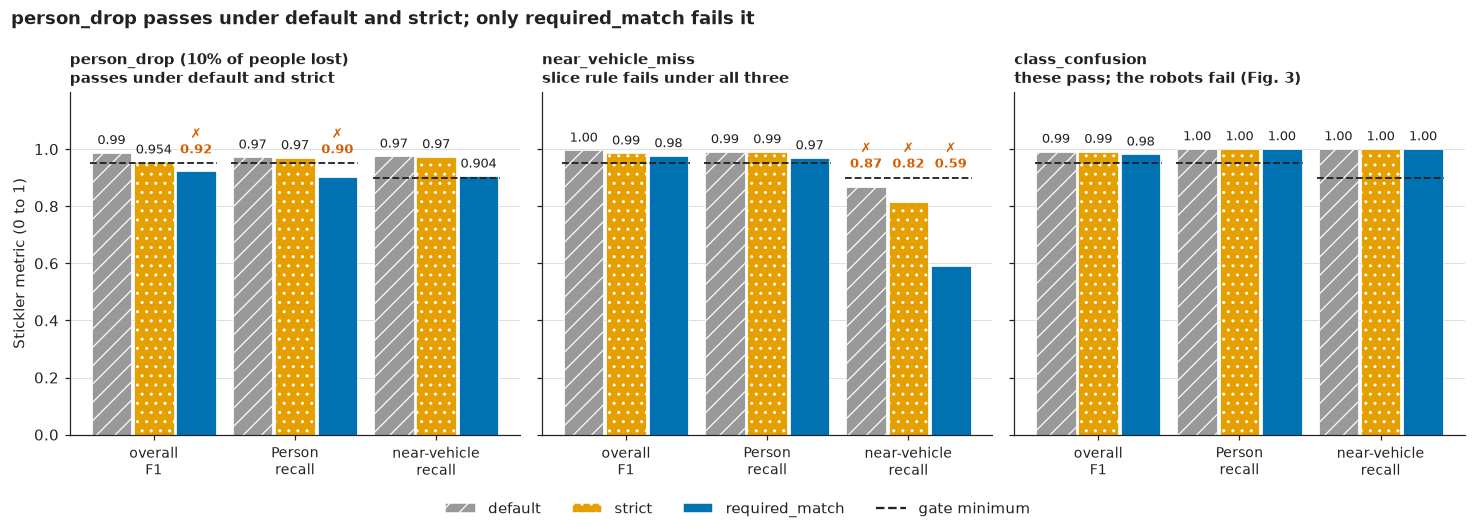

In [12]:
plot_overview()

**Figure 1.** `person_drop` lost about 10% of people, yet its F1 and Person recall clear the 0.95 bar
under `default` and `strict` and fall below it only under `required_match`, while the near-vehicle
slice fails `near_vehicle_miss` under all three schemas, at 0.867, 0.815 and 0.589 (`clean`, not
drawn, scores 1.0 everywhere).

### The checkpoint that loses people next to vehicles

A new checkpoint loses 4 in 10 people within 2 m of a vehicle, and nowhere else.

In [13]:
both = ("default", "strict")
display(metrics_table("near_vehicle_miss", bold={
    "recall (cm_recall)": both, "Person recall": both, "fd": ("strict",),
    "near-vehicle recall": SCHEMA_NAMES, "near-vehicle recall_with_fd": ("strict",)}))
print(f"({scoring_seconds:.0f} s to score all variants)")

near_vehicle_miss,default,strict,required_match
tp,9907,9709,9712
fd,0,198,0
fa,0,0,195
fn,93,93,288
recall (cm_recall),0.991,0.991,0.971
recall_with_fd,0.991,0.971,0.971
F1 (cm_f1),0.995,0.985,0.976
Person recall,0.990,0.990,0.969
Person recall_with_fd,0.990,0.968,0.969
near-vehicle recall,0.867,0.815,0.589


(298 s to score all variants)


In [14]:
# Only required_match shows the loss in stickler's default recall, overall and on the slice.
for schema in ("default", "strict"):
    assert metric("overall", "near_vehicle_miss", schema, "recall") >= 0.99, schema
    assert metric("person", "near_vehicle_miss", schema, "recall") >= 0.98, schema
assert metric("near_vehicle", "near_vehicle_miss", "required_match", "recall") < 0.75
# required_match still passes the usual release bars, so the loss hides there too without the slice.
assert metric("overall", "near_vehicle_miss", "required_match", "f1") >= 0.95
assert metric("person", "near_vehicle_miss", "required_match", "recall") >= 0.95
# strict counts the same losses, as FD: its FD-inclusive recall matches required_match.
assert abs(metric("near_vehicle", "near_vehicle_miss", "strict", "recall_with_fd")
           - metric("near_vehicle", "near_vehicle_miss", "required_match", "recall")) < 0.01

- Under `required_match`, overall F1 is 0.976 and Person recall 0.969, both above a 0.95 release bar,
  while near-vehicle recall is 0.589: the slice rule is what catches it.
- Under `default`, the moved people pair with their ground truth at 5/6 and count as TP. Overall
  recall reads 0.991 and Person recall 0.990; only the dropped people show, and near-vehicle recall
  reads 0.867.
- Under `strict`, the moved people are rejected, but as FDs, and `cm_recall` leaves FD out of the
  denominator. Overall recall again reads 0.991 and Person recall 0.990. The loss is in the counts
  (198 FD) and in `recall_with_fd`: near-vehicle 0.586, within 0.003 of `required_match`. So
  `match_threshold = 1.0` rejects the same pairs; what only `required_match` changes is how a rejected
  pair is counted: FN plus FA, as a detector counts it, so the default recall carries the loss.

> **Warning:** The slice rule fails this checkpoint under all three schemas (0.867, 0.815 and 0.589,
> all below 0.90). `default` and `strict` do not hide it, they understate it: 13% and 18% of the slice
> lost instead of 41%. The checkpoint that passes the gate without `required_match` is `person_drop`,
> in section 5.

### The people it missed

`non_matches` for the frame with the most misses under `required_match`. A moved person is an
unmatched ground truth (FN) plus an unmatched prediction (FA) about 1 m away; a dropped person is an
FN with no partner.

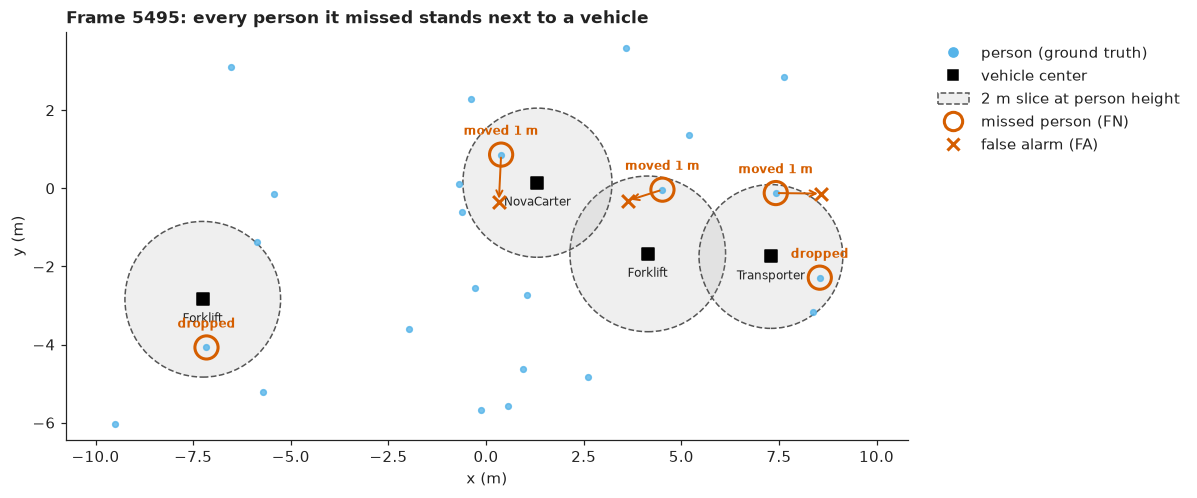

In [15]:
failing_fid = max(GT, key=lambda fid: (FRAME_COUNTS["near_vehicle_miss", "required_match"][fid]["fn"],
                                       -int(fid)))
failing = compare("required_match", GT[failing_fid], VARIANTS["near_vehicle_miss"][failing_fid])
failing_rows = [nm for nm in failing["non_matches"] if OBJECT_ROW.fullmatch(nm["field_path"])]
assert all(nm["ground_truth_value"] is None or is_near_vehicle_person(nm["ground_truth_value"], GT[failing_fid])
           for nm in failing_rows), "a miss outside the slice"
plot_scene(failing_fid, failing_rows)

**Figure 2.** All five people missed in frame 5495 stand within 2 m of a vehicle: three were moved
about 1 m (a ring with an arrow to its false alarm) and two were dropped, while every person farther
away is matched (the shaded disc is the 3D slice cut at the median person height, so it is smaller
around a low robot, about 1.8 m for the Transporter; map cropped to the vehicles plus 3.5 m).

In [16]:
print(f"frame {failing_fid}: {frame_counts(failing)}\n")
for nm in failing_rows:
    distance, vehicle = nearest_vehicle(nm["ground_truth_value"] or nm["prediction_value"], GT[failing_fid])
    print(f"{nm['non_match_type'].value:15} gt {fmt(nm['ground_truth_value']):34}"
          f" pred {fmt(nm['prediction_value']):34} {distance:4.2f} m from a {vehicle}")

frame 5495: {'tp': 45, 'fd': 0, 'fa': 3, 'fn': 5}

false_negative  gt Person   (  8.55,  -2.29,  0.99)   pred -                                  1.61 m from a Transporter
false_negative  gt Person   (  4.52,  -0.03,  0.98)   pred -                                  1.69 m from a Forklift
false_negative  gt Person   (  7.42,  -0.12,  0.81)   pred -                                  1.77 m from a Transporter
false_negative  gt Person   ( -7.16,  -4.07,  0.93)   pred -                                  1.25 m from a Forklift
false_negative  gt Person   (  0.39,   0.86,  0.95)   pred -                                  1.34 m from a NovaCarter
false_alarm     gt -                                  pred Person   (  0.33,  -0.35,  1.05)   1.33 m from a NovaCarter
false_alarm     gt -                                  pred Person   (  8.58,  -0.13,  0.73)   2.14 m from a Transporter
false_alarm     gt -                                  pred Person   (  3.64,  -0.32,  1.02)   1.45 m from a Forklift


## 5. Evidence: the regression that passes, and a rare-class collapse

In [17]:
display(metrics_table("person_drop", only=("fd", "recall (cm_recall)", "recall_with_fd", "F1 (cm_f1)",
                                            "Person recall"), bold={
    "recall (cm_recall)": SCHEMA_NAMES, "F1 (cm_f1)": ("required_match",), "Person recall": SCHEMA_NAMES}))
display(metrics_table("class_confusion", only=("fd", "fa", "fn", "recall (cm_recall)", "F1 (cm_f1)"),
                      bold={"fd": ("default",), "recall (cm_recall)": both}))

person_drop,default,strict,required_match
fd,0,623,0
recall (cm_recall),0.974,0.972,0.911
recall_with_fd,0.974,0.911,0.911
F1 (cm_f1),0.987,0.954,0.924
Person recall,0.971,0.969,0.904


class_confusion,default,strict,required_match
fd,175,185,0
fa,0,0,185
fn,0,0,185
recall (cm_recall),1.000,1.000,0.982
F1 (cm_f1),0.991,0.991,0.982


In [18]:
assert all(metric("overall", "clean", s, "f1") == 1.0 for s in SCHEMA_NAMES)
assert all(metric("near_vehicle", "clean", s, "recall") == 1.0 for s in SCHEMA_NAMES)
# person_drop hides under default: the moved people are TPs.
assert metric("overall", "person_drop", "default", "f1") > 0.98
assert metric("person", "person_drop", "default", "recall") > 0.95
assert metric("person", "person_drop", "required_match", "recall") < 0.92

- `person_drop` loses about 10% of people and passes every gate rule under `default` and `strict`.
  Under `default` the moved people are TPs: recall 0.974, F1 0.987, Person recall 0.971. Under
  `strict` they are FDs that `cm_recall` leaves out: recall 0.972, Person recall 0.969, F1 0.954.
  Under `required_match` recall is 0.911, Person recall 0.904 and F1 0.924, and the gate fails. Its
  frames show the same two shapes as frame 5495: dropped (FN) and moved (FN plus FA).
- `class_confusion`: the swapped robots are FDs under `default` and `strict`, and FN plus FA under
  `required_match`. Overall F1 stays at 0.98 or above under every schema, and under `default` and
  `strict` `cm_recall` even reads 1.0. NovaCarter and Transporter are 400 of the 10,000 objects (4%),
  and the 185 swapped labels 1.85%, so only the per-class split shows the collapse.
- `clean` (not shown) scores 1.0 on every metric under every schema, as the next cell asserts: jitter
  inside tolerance is not a regression.

Person is 92% of the objects, so a regression spread over all people moves overall F1 almost as far as
Person recall, once it is counted. A regression hides in the overall number when it hits a small
group: the robots here, or the people near vehicles in section 4.

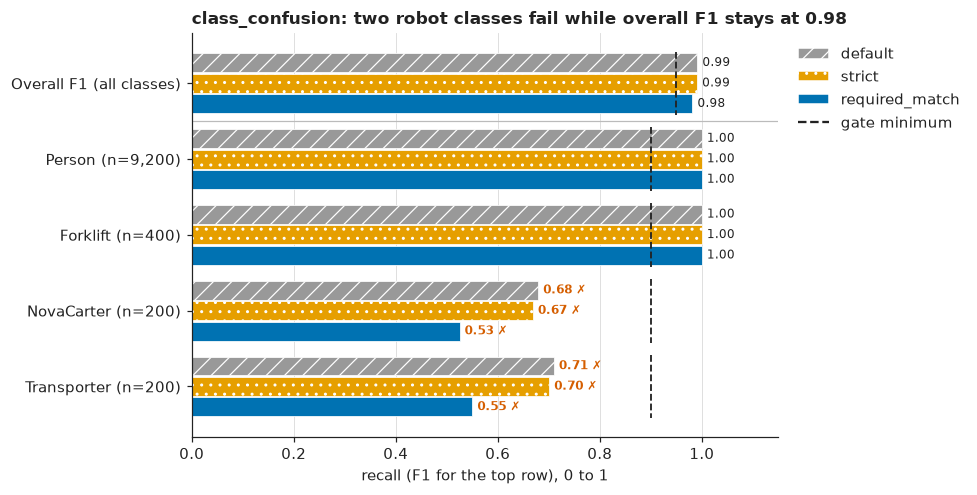

In [19]:
plot_class_confusion()

**Figure 3.** NovaCarter and Transporter recall fall to 0.68 and 0.71 under `default` and to 0.53 and
0.55 under `required_match`, while overall F1 stays at 0.98 or above, because the two robot classes
are 4% of the objects; `default`'s 0.68 is inflated, because in the NovaCarter-only rescoring 43 of
the 95 NovaCarters without their own prediction pair with the other robot's relabelled one, 38 as FDs
that `cm_recall` leaves out and 5 as TPs (class plus two axes scores 5/6).

Per-class recall for every variant (✗ marks a value below the 0.90 class gate):

In [20]:
display(per_class_table())

variant,schema,Forklift recall,NovaCarter recall,Person recall,Transporter recall
near_vehicle_miss,default,✓ 1.000,✓ 1.000,✓ 0.990,✓ 1.000
near_vehicle_miss,strict,✓ 1.000,✓ 1.000,✓ 0.990,✓ 1.000
near_vehicle_miss,required_match,✓ 1.000,✓ 1.000,✓ 0.969,✓ 1.000
clean,default,✓ 1.000,✓ 1.000,✓ 1.000,✓ 1.000
clean,strict,✓ 1.000,✓ 1.000,✓ 1.000,✓ 1.000
clean,required_match,✓ 1.000,✓ 1.000,✓ 1.000,✓ 1.000
person_drop,default,✓ 1.000,✓ 1.000,✓ 0.971,✓ 1.000
person_drop,strict,✓ 1.000,✓ 1.000,✓ 0.969,✓ 1.000
person_drop,required_match,✓ 1.000,✓ 1.000,✓ 0.904,✓ 1.000
class_confusion,default,✓ 1.000,✗ 0.679 < 0.90,✓ 1.000,✗ 0.710 < 0.90


<details>
<summary>Why <code>default</code> counts 175 FDs for 185 swapped robots</summary>

Under `default`, 10 of the 185 swapped robots count as TPs: each pairs with the other robot in the
frame, which has the predicted class and is within 0.5 m on two axes, so the pair scores 3 + 2 of 6
weight, above 0.7. `strict` and `required_match` reject those pairs, so `strict` counts all 185 as FD
and `required_match` as 185 FN plus 185 FA.

</details>

## 6. Cross-check: a nuScenes-style greedy matcher

The matcher in Setup (`greedy_center_distance`) does not use stickler. Like nuScenes, it matches
within each class only, by center distance on the ground plane, greedily in prediction order (the
synthetic predictions have no confidence to sort by), within 0.5 m. It has no FD: an object is matched
or it is not.

Two differences from the stickler schemas: its gate is a 0.5 m circle in x and y and ignores z, while
stickler checks 0.5 m on each of x, y and z; and greedy order can miss the assignment with the most
matches when two people are close. The jitter here stays inside both gates: at most 0.42 m on the
ground plane and 0.3 m in z.

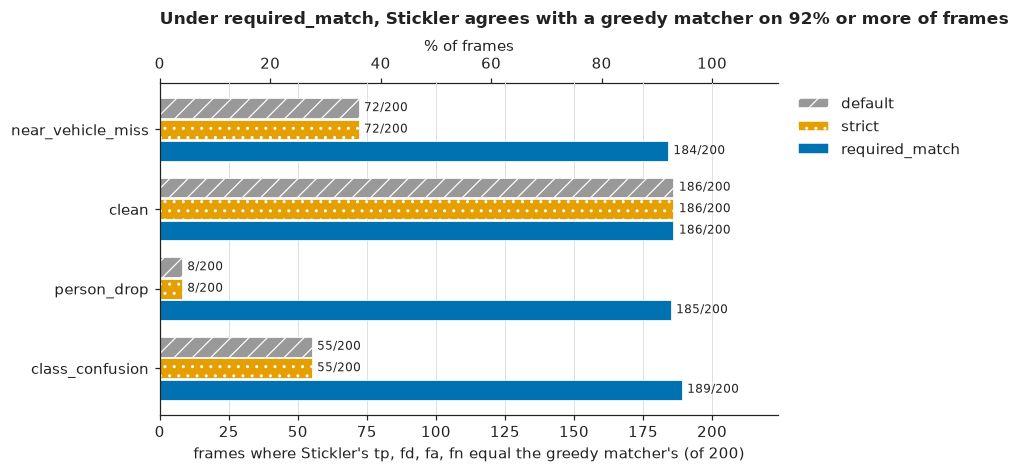

In [21]:
RESULTS["greedy"] = {}
for name, preds in VARIANTS.items():
    per_frame = {fid: greedy_center_distance(GT[fid], preds[fid]) for fid in GT}
    RESULTS["greedy"][name] = {
        **{k: sum(c[k] for c in per_frame.values()) for k in COUNT_KEYS},
        "equal_frames": {s: sum(FRAME_COUNTS[name, s][fid] == per_frame[fid] for fid in GT)
                         for s in SCHEMA_NAMES}}
    # Every pair inside the greedy gate is inside the stickler gate here (z jitter stays under
    # 0.5 m), and the Hungarian assignment maximizes matches, so required_match never has fewer TPs.
    assert all(FRAME_COUNTS[name, "required_match"][fid]["tp"] >= per_frame[fid]["tp"] for fid in GT), name
plot_agreement()

**Figure 4.** Under `required_match`, Stickler gives the same counts as the independent greedy
matcher on 184 to 189 of 200 frames, against as few as 8 under `default` and `strict`, where a moved
person is a TP or an FD instead of an FN plus an FA.

In [22]:
print(f"{'variant':18} {'matcher':16} {'tp':>6} {'fd':>4} {'fa':>4} {'fn':>4}  frames equal to greedy")
for name in VARIANTS:
    greedy = RESULTS["greedy"][name]
    print(f"{name:18} {'greedy':16} {greedy['tp']:>6} {greedy['fd']:>4} {greedy['fa']:>4} {greedy['fn']:>4}")
    for s in SCHEMA_NAMES:
        c = RESULTS["overall"][f"{name}/{s}"]
        print(f"{'':18} {s:16} {c['tp']:>6} {c['fd']:>4} {c['fa']:>4} {c['fn']:>4}"
              f"  {greedy['equal_frames'][s]}/{len(GT)}")

variant            matcher              tp   fd   fa   fn  frames equal to greedy
near_vehicle_miss  greedy             9696    0  211  304
                   default            9907    0    0   93  72/200
                   strict             9709  198    0   93  72/200
                   required_match     9712    0  195  288  184/200
clean              greedy             9986    0   14   14
                   default           10000    0    0    0  186/200
                   strict            10000    0    0    0  186/200
                   required_match    10000    0    0    0  186/200
person_drop        greedy             9099    0  636  901
                   default            9735    0    0  265  8/200
                   strict             9112  623    0  265  8/200
                   required_match     9114    0  621  886  185/200
class_confusion    greedy             9802    0  198  198
                   default            9825  175    0    0  55/200
                   stri

Where `required_match` and the greedy matcher differ, stickler has a few more TPs (14 of 10,000 in
`clean`). In `clean` every difference is greedy order, since all jitter is inside both gates: the
greedy matcher lets a prediction take the nearest free ground truth even when that strands a
neighbor, while the Hungarian assignment maximizes the number of matches. Elsewhere a second cause can
add to it: the box reaches 0.71 m on a diagonal, where the circle stops at 0.5 m. Under `default` and
`strict` the counts also differ by kind: a moved person is a TP or an FD, where the greedy matcher has
one FN plus one FA.

## 7. Use it as a CI gate

A release gate needs a deterministic yes or no with reasons. `gate(name, schema, thresholds=GATE)`
in Setup reads Stickler's reported metrics and fails on any of four rules from Configuration:

- overall F1 (`cm_f1`) below 0.95
- Person recall (`cm_recall`) below 0.95
- any class recall below 0.90
- near-vehicle recall below 0.90

It returns `{"passed": bool, "reasons": [...]}`. The printout is the CI log view.

In [23]:
RESULTS["gate"] = {f"{name}/{schema}": gate(name, schema) for name in VARIANTS for schema in SCHEMA_NAMES}
for key, decision in RESULTS["gate"].items():
    name, schema = key.split("/")
    print(f"{name:18} {schema:15} {'PASS' if decision['passed'] else 'FAIL'}  {'; '.join(decision['reasons'])}")

near_vehicle_miss  default         FAIL  near-vehicle recall 0.867332 < 0.9
near_vehicle_miss  strict          FAIL  near-vehicle recall 0.815476 < 0.9
near_vehicle_miss  required_match  FAIL  near-vehicle recall 0.589158 < 0.9
clean              default         PASS  
clean              strict          PASS  
clean              required_match  PASS  
person_drop        default         PASS  
person_drop        strict          PASS  
person_drop        required_match  FAIL  overall F1 0.923638 < 0.95; Person recall 0.903696 < 0.95
class_confusion    default         FAIL  NovaCarter recall 0.679012 < 0.9; Transporter recall 0.709877 < 0.9
class_confusion    strict          FAIL  NovaCarter recall 0.66879 < 0.9; Transporter recall 0.700637 < 0.9
class_confusion    required_match  FAIL  NovaCarter recall 0.525 < 0.9; Transporter recall 0.55 < 0.9


In [24]:
GATE_EXPECTED = {
    # The headline fails only the slice rule, under every schema.
    "near_vehicle_miss/default": ["near-vehicle recall"],
    "near_vehicle_miss/strict": ["near-vehicle recall"],
    "near_vehicle_miss/required_match": ["near-vehicle recall"],
    "clean/default": [], "clean/strict": [], "clean/required_match": [],
    # person_drop hides under default and strict.
    "person_drop/default": [], "person_drop/strict": [],
    "person_drop/required_match": ["overall F1", "Person recall"],
    "class_confusion/default": ["NovaCarter recall", "Transporter recall"],
    "class_confusion/strict": ["NovaCarter recall", "Transporter recall"],
    "class_confusion/required_match": ["NovaCarter recall", "Transporter recall"],
}
assert {key: failed_rules(*key.split("/")) for key in RESULTS["gate"]} == GATE_EXPECTED
display(gate_table())

variant,schema,overall F1,Person recall,lowest class recall,near-vehicle recall,decision
near_vehicle_miss,default,✓ 0.995,✓ 0.990,Person ✓ 0.990,✗ 0.867 < 0.90,FAIL
near_vehicle_miss,strict,✓ 0.985,✓ 0.990,Person ✓ 0.990,✗ 0.815 < 0.90,FAIL
near_vehicle_miss,required_match,✓ 0.976,✓ 0.969,Person ✓ 0.969,✗ 0.589 < 0.90,FAIL
clean,default,✓ 1.000,✓ 1.000,Forklift ✓ 1.000,✓ 1.000,PASS
clean,strict,✓ 1.000,✓ 1.000,Forklift ✓ 1.000,✓ 1.000,PASS
clean,required_match,✓ 1.000,✓ 1.000,Forklift ✓ 1.000,✓ 1.000,PASS
person_drop,default,✓ 0.987,✓ 0.971,Person ✓ 0.971,✓ 0.974,PASS
person_drop,strict,✓ 0.954,✓ 0.969,Person ✓ 0.969,✓ 0.972,PASS
person_drop,required_match,✗ 0.924 < 0.95,✗ 0.904 < 0.95,Person ✓ 0.904,✓ 0.904,FAIL
class_confusion,default,✓ 0.991,✓ 1.000,NovaCarter ✗ 0.679 < 0.90,✓ 1.000,FAIL


**Table 1.** `person_drop` passes the gate under `default` and `strict` and fails only under
`required_match`, while `near_vehicle_miss` fails the slice rule and `class_confusion` the robot class
rules under every schema.

The slice rule catches the headline regression whatever the schema; without it, all three schemas
would pass `near_vehicle_miss`. `required_match` is what makes the rest of the report, and the
`person_drop` regression, count like a detector.

> **Tip:** In CI, run `gate()` on your checkpoint, print `decision["reasons"]`, and end the job with
> `sys.exit(0 if decision["passed"] else 1)`.

## 8. Limits

> **Warning:** The predictions are synthetic perturbations of the ground truth, not a detector's
> output. These counts show how the metric behaves, not how good any detector is. The position gate is
> a per-axis 0.5 m box: no 3D center distance, no IoU, no orientation.

- No confidence, so no AP: counts at one operating point.
- `3d_bounding_box_rotation` is not scored.
- `required_match` accepts only `str`, `int`, `float` and `bool` fields, so the position is three
  floats, not a tuple or a point.
- The slice uses the 3D distance between box centers, not ground-plane proximity: a person 2 m from
  a low robot's center in 3D is closer than 2 m on the floor.
- One scene, 200 of its 9,000 frames, no tracking.

## 9. Next steps

**Bring your own detector.** Give each checkpoint as
`{frame_id: [{"cls": str, "x": float, "y": float, "z": float}, ...]}` for the frame ids in `GT`, in
meters, box center; the frame ids are `str` keys, as in the dataset file. Filter your detections by
score at your operating point first: there is no AP here. Replace `VARIANTS` with your checkpoints and
rerun from "Score all variants". The asserts check the shipped synthetic variants, so drop them for
your own.

Cost: a pass over 200 frames under one schema takes about 5 s on average. That is the measured
300 s of scoring divided by its 60 passes: 4 checkpoints, 3 schemas, and 5 passes each (all classes,
Person, and the three other classes alone).

- A 3D center-distance field: `PointDistanceComparator` (#632, open). It needs `required_match` to
  accept a point field, which #539 refuses today.
- Orientation: `AngleComparator` (#633, open).

## Takeaway

> **Takeaway.** Only `required_match` makes Stickler's default report count like a detector. Without
> it, a checkpoint that lost about 10% of people reads recall and Person recall 0.97 and passes the
> gate; with it, they read 0.91 and 0.90 and the gate fails. `strict` with `recall_with_fd=True`
> reaches the same recall, but still labels the misses FD and agrees with a greedy matcher on only 8 to
> 72 of 200 frames. A slice rule on people near vehicles catches the near-vehicle regression
> under every schema, but only `required_match` shows its real size: 0.589, not 0.867. With it,
> Stickler also agrees with an independent nuScenes-style matcher on 92% or more of frames.

## Reproducibility

The same data revision, seeds, configuration and stickler tree give the same hash; cite it with any
number you quote. It covers `RESULTS`: every count and metric, the greedy cross-check and the gate
decisions.

In [25]:
# The hash of RESULTS at the revision, seeds and stickler tree above.
EXPECTED_RESULTS_SHA256 = "8bf2113d1dfb43ba4181dd2fba1fbe3b79325bf54ae17d5a068abd765279f6da"
digest = hashlib.sha256(json.dumps(RESULTS, sort_keys=True).encode()).hexdigest()
print("results sha256:", digest)
print(f"total runtime : {time.perf_counter() - NOTEBOOK_START:.0f} s")
assert digest == EXPECTED_RESULTS_SHA256, (
    "Results changed. If the change is intended (new stickler behavior, revision or seeds), "
    "update EXPECTED_RESULTS_SHA256 in this cell.")

results sha256: 8bf2113d1dfb43ba4181dd2fba1fbe3b79325bf54ae17d5a068abd765279f6da
total runtime : 303 s


## Citation

The dataset card asks users to cite its papers; for `MTMC_Tracking_2025` these are:

```bibtex
@InProceedings{Tang25AICity25,
  author    = {Zheng Tang and Shuo Wang and David C. Anastasiu and Ming-Ching Chang and Anuj Sharma and Quan Kong and Norimasa Kobori and Munkhjargal Gochoo and Ganzorig Batnasan and Munkh-Erdene Otgonbold and Fady Alnajjar and Jun-Wei Hsieh and Tomasz Kornuta and Xiaolong Li and Yilin Zhao and Han Zhang and Subhashree Radhakrishnan and Arihant Jain and Ratnesh Kumar and Vidya N. Murali and Yuxing Wang and Sameer Satish Pusegaonkar and Yizhou Wang and Sujit Biswas and Xunlei Wu and Zhedong Zheng and Pranamesh Chakraborty and Rama Chellappa},
  title     = {The 9th {AI} {C}ity {C}hallenge},
  booktitle = {Proc. ICCV Workshops},
  pages     = {5526--5535},
  address   = {Honolulu, HI, USA},
  year      = {2025}
}

@InProceedings{Wang26PAISS,
  author    = {Yuxing Wang and Yizhou Wang and Anqi Li and Shuo Wang and Sameer Satish Pusegaonkar and Haoquan Liang and Jiajun Li and Shenxin Jiang and Jianhe Yuan and Shangru Li and Tongwei Dai and Zihao Chen and David C. Anastasiu and Sujit Biswas and Xunlei Wu and Zheng Tang},
  title     = {Physical {AI} {S}mart {S}paces: {A} large-scale benchmark for multi-camera {3D} perception in smart spaces},
  booktitle = {Proc. NeurIPS},
  address   = {Atlanta, GA, USA},
  note      = {arXiv:2610.02580},
  year      = {2026}
}
```

The full list is in the [dataset card](https://huggingface.co/datasets/nvidia/PhysicalAI-SmartSpaces).